# How do flagged accounts look on their own?

Compare account-game profiles with at least 100 positive-stake wagers. For each flagged profile, select the nearest unflagged profile by wager count within the same game. Controls may be reused. This is a descriptive comparison with accounts outside the retained links. Their actual coordination status is unknown.

In [1]:
%matplotlib inline
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from rings import classify_pairs, connected_groups

con = duckdb.connect("../private/wagers.duckdb", read_only=True,
                     config={"threads": 4, "memory_limit": "3GB",
                             "temp_directory": "../private/audit-spill"})

con.execute("SET VARIABLE min_mirrors = 30")
con.execute(Path("compare_pairs.sql").read_text())
pairs = classify_pairs(con.sql("SELECT * FROM pair_metrics").df())
links = pairs[pairs["tier"].isin(["A", "B"])]
flagged = pd.DataFrame({"member": pd.concat([links.account_a, links.account_b]).unique()})
con.register("flagged", flagged)
profiles = con.sql('''
    WITH ordered AS (
        SELECT member, game, bet,
               epoch(min_time_stamp) - epoch(lag(min_time_stamp) OVER history) AS gap,
               lag(bet) OVER history AS previous_stake
        FROM wagers
        WHERE game IN ('traditional', 'non_com', 'fab4', 'super_98', 'lucky_sq', 'dragon_tiger')
          AND member IS NOT NULL AND min_time_stamp IS NOT NULL AND bet > 0 AND isfinite(bet)
        WINDOW history AS (
            PARTITION BY member, game ORDER BY min_time_stamp, tableNO, shoe_ref, shoe_hand, bet
        )
    )
    SELECT o.member, game, count(*) AS hands, f.member IS NOT NULL AS flagged,
           median(gap) FILTER (WHERE gap > 0 AND gap <= 1800) AS median_gap,
           avg((bet = previous_stake)::INT) FILTER (WHERE gap > 0 AND gap <= 1800) AS repeat_share,
           stddev_pop(bet) / avg(bet) AS stake_cv
    FROM ordered o LEFT JOIN flagged f USING (member)
    GROUP BY o.member, game, f.member HAVING count(*) >= 100
''').df()
con.close()

,profiles,unique_accounts,median_hands,median_gap,repeat_share,stake_cv
cohort,,,,,,
Flagged,192,152,348.0,37.588,0.613,0.563
Matched,192,182,348.0,43.850,0.335,0.776


Unmatched flagged profiles: 0


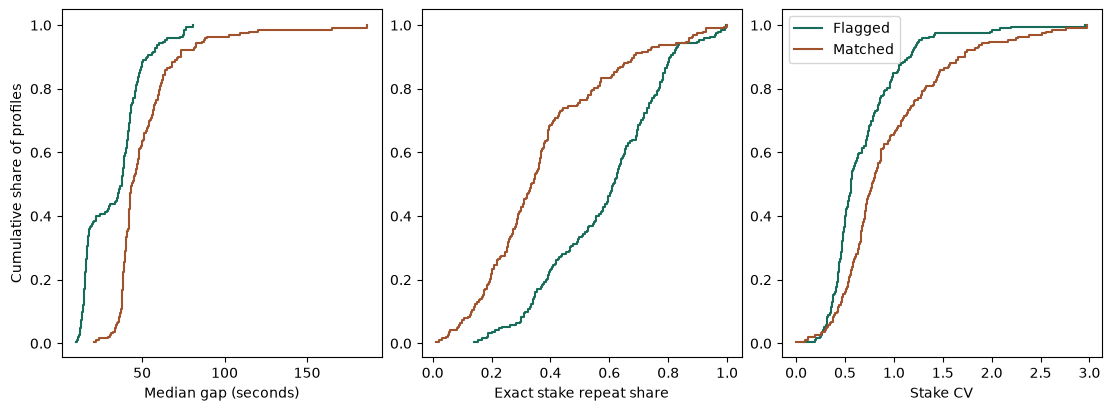

In [2]:
import numpy as np

matches = []
for game, group in profiles.groupby("game"):
    cases = group[group.flagged].sort_values(["hands", "member"])
    controls = group[~group.flagged].sort_values(["hands", "member"])
    if cases.empty or controls.empty:
        continue
    control_volume = np.log(controls.hands.to_numpy())
    case_volume = np.log(cases.hands.to_numpy())
    upper = np.searchsorted(control_volume, case_volume).clip(0, len(controls) - 1)
    lower = (upper - 1).clip(0)
    nearest = np.where(abs(control_volume[lower] - case_volume) <=
                       abs(control_volume[upper] - case_volume), lower, upper)
    matches.append(pd.concat([cases.assign(cohort="Flagged"),
                              controls.iloc[nearest].assign(cohort="Matched")]))
matched = pd.concat(matches, ignore_index=True)
display(matched.groupby("cohort").agg(
    profiles=("member", "size"), unique_accounts=("member", "nunique"),
    median_hands=("hands", "median"), median_gap=("median_gap", "median"),
    repeat_share=("repeat_share", "median"), stake_cv=("stake_cv", "median"),
).round(3))
print("Unmatched flagged profiles:", int(profiles.flagged.sum()) - len(matched) // 2)

fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
for ax, metric, label in zip(axes, ["median_gap", "repeat_share", "stake_cv"],
                             ["Median gap (seconds)", "Exact stake repeat share", "Stake CV"]):
    for cohort, color in [("Flagged", "#176c59"), ("Matched", "#a0522d")]:
        values = np.sort(matched.loc[matched.cohort == cohort, metric].dropna())
        ax.step(values, np.arange(1, len(values) + 1) / len(values),
                where="post", label=cohort, color=color)
    ax.set_xlabel(label)
axes[0].set_ylabel("Cumulative share of profiles")
axes[-1].legend()
plt.show()

The charts compare full-period profiles, including play outside the mirrored rounds. Differences can reflect how the audit selects links, as well as other unmatched factors. Multiple game profiles can belong to one account, and controls can repeat. The comparisons describe these cohorts rather than estimate detection accuracy.